In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")



In [69]:
# Usamos solo invoice, pero preparamos la fecha
df_ventas = invoice.copy()
df_ventas['InvoiceDate'] = pd.to_datetime(df_ventas['InvoiceDate'])
df_ventas['Mes_Año'] = df_ventas['InvoiceDate'].dt.to_period('M')

# Agrupar las ventas totales por mes
ventas_mensuales = df_ventas.groupby('Mes_Año')['Total'].sum()
display(ventas_mensuales.head(2))
# Convertir el índice (period) a string para que matplotlib lo grafique sin problemas
ventas_mensuales.index = ventas_mensuales.index.astype(str)
display(ventas_mensuales.head(2))

# Cruzar Tracks con Media Types para tener el nombre del formato
df_pistas_media = pd.merge(track, media, on="MediaTypeId", suffixes=('_Track', '_Media'))

# Convertir milisegundos a minutos y bytes a megabytes
df_pistas_media['Minutos'] = df_pistas_media['Milliseconds'] / 60000
df_pistas_media['Megabytes'] = df_pistas_media['Bytes'] / (1024 * 1024)

# Filtrar valores atípicos extremos para una mejor visualización
df_scatter = df_pistas_media[df_pistas_media['Minutos'] < 20]
df_scatter.head()


# Cruzar líneas de factura con canciones y luego con géneros
df_inv_trk = pd.merge(invoice_line, track, on="TrackId")
df_ventas_generos = pd.merge(df_inv_trk, genre, on="GenreId", suffixes=('_Track', '_Genre'))

# Sumar las ventas (Quantity * UnitPrice) por género
df_ventas_generos['Monto'] = df_ventas_generos['UnitPrice_x'] * df_ventas_generos['Quantity']
ingresos_por_genero = df_ventas_generos.groupby('Name_Genre')['Monto'].sum().sort_values(ascending=False)

# Tomar el top 5
top_5_generos = ingresos_por_genero.head(5)
top_5_generos

invoice["InvoiceDate"] = pd.to_datetime(invoice["InvoiceDate"])
invoice["Anio"] = invoice["InvoiceDate"].dt.year
invoice["Mes"] = invoice["InvoiceDate"].dt.month

pistas = (track
.merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
.merge(media.rename(columns={"Name": "Medio"}), on="MediaTypeId")
.merge(album, on="AlbumId")
.merge(artist.rename(columns={"Name": "Artista"}), on="ArtistId")
.rename(columns={"Name": "Pista"}))
pistas["Minutos"] = pistas["Milliseconds"] / 60000
pistas["MB"] = pistas["Bytes"] / 1e6

# Solo audio y pistas de menos de 15 min
audio = pistas[(pistas["Minutos"] < 15) & ~pistas["Medio"].str.contains("video")]
# Los 6 géneros con más pistas
top_generos = audio["Genero"].value_counts().head(6).index
musica_top = audio[audio["Genero"].isin(top_generos)]

Mes_Año
2021-01    35.64
2021-02    37.62
Freq: M, Name: Total, dtype: float64

Mes_Año
2021-01    35.64
2021-02    37.62
Name: Total, dtype: float64

<Axes: xlabel='count', ylabel='Country'>

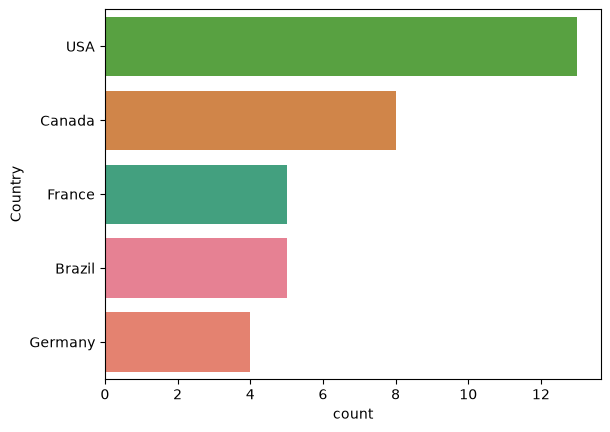

In [70]:
#1

df_1 = customer
top_5 = df_1.groupby("Country")["CustomerId"].count().sort_values(ascending = False).nlargest(5).index
sns.countplot(data = df_1, y = "Country", order = top_5, hue = "Country")

<Axes: xlabel='BillingCountry', ylabel='Total'>

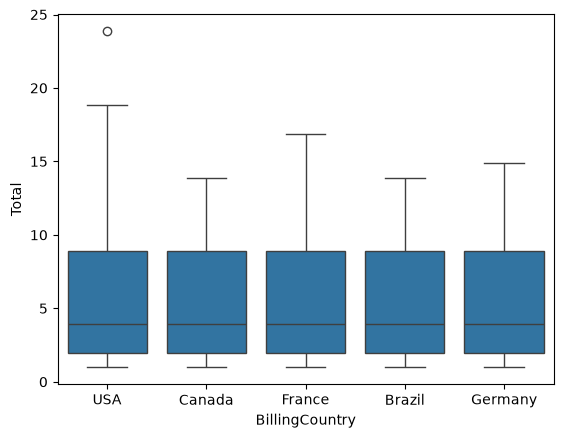

In [71]:
#2
df_2 = invoice
top_5 = df_2.groupby("BillingCountry")["Total"].sum().sort_values(ascending = False).nlargest(5).index
sns.boxplot(data = df_2, y = "Total", x = "BillingCountry", order= top_5)

<Axes: xlabel='SupportRepId', ylabel='Total'>

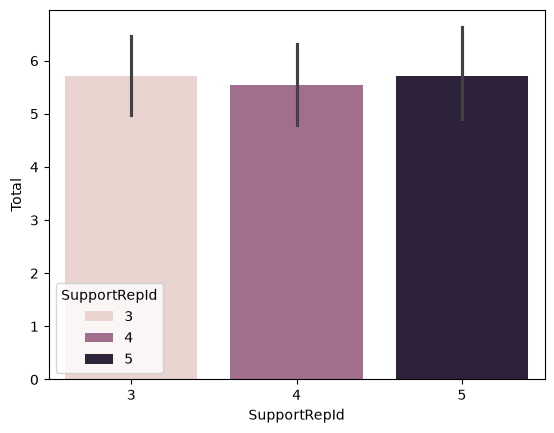

In [72]:
df_3 = invoice

df_3 = df_3.merge(
    customer,
    on = "CustomerId",
    how = "left"
)

df_3 = df_3.merge(
    employee,
    left_on ='SupportRepId',
    right_on = 'EmployeeId',
    how = 'left'
)

sns.barplot(data = df_3, y = 'Total', x = 'SupportRepId', hue = 'SupportRepId')

<Axes: xlabel='Name_x', ylabel='Milliseconds'>

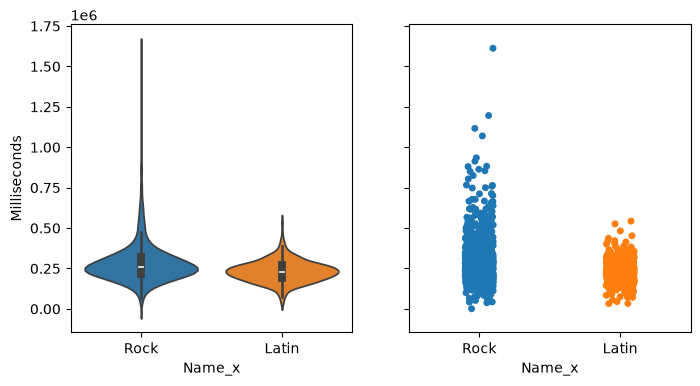

In [73]:
#4

df_4=genre.merge(track, on="GenreId",how="left")

df_4=df_4[(df_4["Name_x"]=="Rock")|(df_4["Name_x"]=="Latin")]

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.violinplot(data=df_4, x="Name_x", y="Milliseconds",hue="Name_x", ax=axes[0])
sns.stripplot(data=df_4, x="Name_x", y="Milliseconds",hue="Name_x", ax=axes[1])

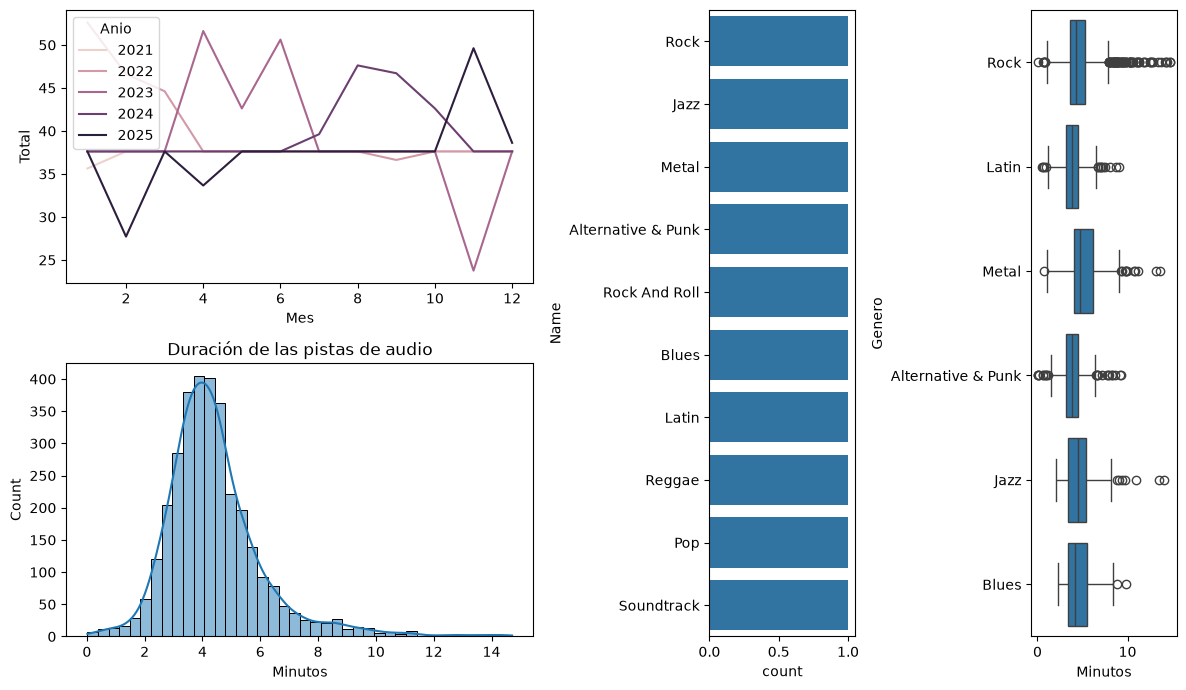

In [78]:
#5
fig, axd = plt.subplot_mosaic("AABC;DDBC", figsize=(12, 7))

mensual = invoice.groupby(["Anio", "Mes"], as_index=False)["Total"].sum()
sns.lineplot(data=mensual, x="Mes", y="Total", hue="Anio", ax = axd["A"])
plt.title("Ingresos mensuales por año")

orden = genre["Name"].value_counts().head(10).index
sns.countplot(data=genre, y="Name", order=orden, ax = axd["B"])
plt.title("Número de pistas por género (top 10)")

sns.boxplot(data=musica_top, x="Minutos", y="Genero", order=top_generos, ax = axd["C"])
plt.title("Duración por género")

sns.histplot(data=audio, x="Minutos", bins=40, kde=True, ax = axd["D"])
plt.title("Duración de las pistas de audio")

fig.tight_layout()



<Axes: xlabel='año', ylabel='BillingCountry'>

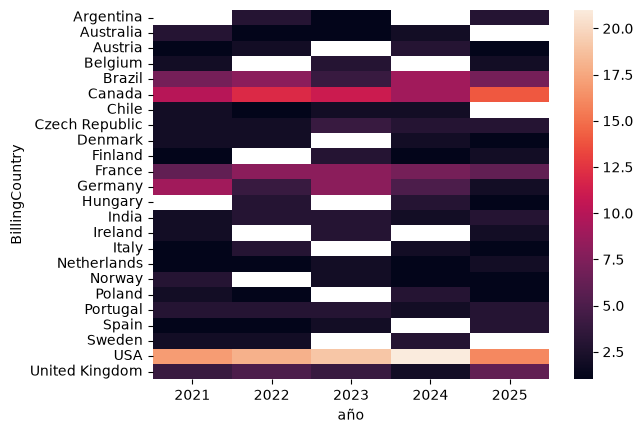

In [75]:
#6

df_6=invoice
df_6["InvoiceDate"]=pd.to_datetime(df_6["InvoiceDate"])
df_6["año"]=df_6["InvoiceDate"].dt.year
df_6=df_6.pivot_table(
    values="InvoiceId",
    columns="año",
    index="BillingCountry",
    aggfunc="count"
)

sns.heatmap(df_6)

In [76]:
genre.head()

,GenreId,Name
0,1,Rock
1,2,Jazz
2,3,Metal
3,4,Alternative & Punk
4,5,Rock And Roll
